# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Kendrick Raphael Ticoalu
- **Email:** kendrickraphael@gmail.com
- **ID Dicoding:** satusatunyaken

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** "Bagaimana perkembangan jumlah pesanan dan total nilai pembayaran (GMV) per bulan pada transaksi Olist selama periode data 2016–2018?"
- **Pertanyaan 2:** "Bagaimana tingkat keterlambatan pengiriman pesanan yang telah terkirim menurut negara bagian pelanggan selama periode data 2016–2018, dan negara bagian mana yang perlu diprioritaskan?"

## Import Semua Packages/Library yang Digunakan

In [1]:
# @title
import os
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
DATA_DIR = "data"

## Data Wrangling

### Gathering Data

#### Load df ...

In [8]:
! git clone https://github.com/0neAnd0nlyKen/fundamental-analisis-data

Cloning into 'fundamental-analisis-data'...
remote: Enumerating objects: 13, done.
remote: Counting objects: 100% (13/13), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 13 (delta 0), reused 13 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (13/13), 42.30 MiB | 18.42 MiB/s, done.
Updating files: 100% (10/10), done.


In [10]:
DATA_DIR = "/content/fundamental-analisis-data/E-Commerce Public Dataset"

# Mapping file names based on what is available in the cloned directory
# (They are named without the 'olist_' prefix in this specific repository)
orders_path = os.path.join(DATA_DIR, "orders_dataset.csv")
items_path = os.path.join(DATA_DIR, "order_items_dataset.csv")
payments_path = os.path.join(DATA_DIR, "order_payments_dataset.csv")
customers_path = os.path.join(DATA_DIR, "customers_dataset.csv")
reviews_path = os.path.join(DATA_DIR, "order_reviews_dataset.csv")
products_path = os.path.join(DATA_DIR, "products_dataset.csv")

# Load datasets
orders = pd.read_csv(orders_path)
items = pd.read_csv(items_path)
payments = pd.read_csv(payments_path)
customers = pd.read_csv(customers_path)
reviews = pd.read_csv(reviews_path) if os.path.exists(reviews_path) else pd.DataFrame()
products = pd.read_csv(products_path) if os.path.exists(products_path) else pd.DataFrame()

# Display metadata
print("Orders:", orders.shape)
print("Items:", items.shape)
print("Payments:", payments.shape)
print("Customers:", customers.shape)
print("Reviews:", reviews.shape)
print("Products:", products.shape)

Orders: (99441, 8)
Items: (112650, 7)
Payments: (103886, 5)
Customers: (99441, 5)
Reviews: (99224, 7)
Products: (32951, 9)


**Insight:** (Opsional)
- Dataset utama terdiri dari tabel pesanan, item pesanan, pembayaran, dan pelanggan.
- Tabel-tabel tersebut dihubungkan menggunakan order_id dan customer_id.
- Tabel ulasan dan produk dimuat jika tersedia, tetapi tidak menjadi syarat untuk menjawab dua pertanyaan bisnis utama.

### Assessing Data

#### Identifying ... problem

In [11]:
print("=== INFO ORDERS ===")
orders.info()
print("\n=== MISSING VALUE ===")
display(pd.DataFrame({
    "missing_count": orders.isna().sum(),
    "missing_pct": (orders.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False))
print("\n=== DUPLIKASI ===")
print({
    "orders_duplicate_rows": int(orders.duplicated().sum()),
    "items_duplicate_rows": int(items.duplicated().sum()),
    "payments_duplicate_rows": int(payments.duplicated().sum()),
    "customers_duplicate_rows": int(customers.duplicated().sum()),
})
print("\n=== RENTANG TANGGAL ===")
for col in ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]:
    if col in orders:
        parsed = pd.to_datetime(orders[col], errors="coerce")
        print(col, parsed.min(), "s/d", parsed.max(), "| invalid:", int(parsed.isna().sum()))
print("\n=== PEMERIKSAAN PEMBAYARAN ===")
display(payments[["payment_value", "payment_installments"]].describe())

=== INFO ORDERS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

=== MISSING VALUE ===


,missing_count,missing_pct
order_delivered_customer_date,2965,2.98
order_delivered_carrier_date,1783,1.79
order_approved_at,160,0.16
order_id,0,0.00
order_purchase_timestamp,0,0.00
order_status,0,0.00
customer_id,0,0.00
order_estimated_delivery_date,0,0.00



=== DUPLIKASI ===
{'orders_duplicate_rows': 0, 'items_duplicate_rows': 0, 'payments_duplicate_rows': 0, 'customers_duplicate_rows': 0}

=== RENTANG TANGGAL ===
order_purchase_timestamp 2016-09-04 21:15:19 s/d 2018-10-17 17:30:18 | invalid: 0
order_delivered_customer_date 2016-10-11 13:46:32 s/d 2018-10-17 13:22:46 | invalid: 2965
order_estimated_delivery_date 2016-09-30 00:00:00 s/d 2018-11-12 00:00:00 | invalid: 0

=== PEMERIKSAAN PEMBAYARAN ===


,payment_value,payment_installments
count,103886.000000,103886.000000
mean,154.100380,2.853349
std,217.494064,2.687051
min,0.000000,0.000000
25%,56.790000,1.000000
50%,100.000000,1.000000
75%,171.837500,4.000000
max,13664.080000,24.000000


**Steps to Take:**
- Missing value: beberapa pesanan dapat tidak memiliki tanggal pengiriman aktual, misalnya karena status belum terkirim atau pembatalan. Tanggal tersebut tidak boleh diisi secara sembarang; analisis keterlambatan hanya memakai pesanan berstatus delivered dengan tanggal aktual dan estimasi yang valid.
- Duplikasi: baris duplikat identik pada tabel akan dihapus. Untuk tabel pesanan, order_id harus unik; duplikasi berdasarkan ID diperiksa secara khusus.
- Invalid/inconsistent value: kolom waktu dikonversi menjadi tipe datetime. Nilai pembayaran negatif atau tanggal yang tidak dapat diparse diperiksa sebelum analisis.
- Granularitas tabel: satu pesanan dapat memiliki beberapa item dan beberapa baris pembayaran. Karena itu, item dan pembayaran harus diagregasi per order_id sebelum digabung agar jumlah pesanan tidak terduplikasi.

**Insight:** (Opsional)
- xxx
- xxx

### Cleaning Data

#### Fixing ... problem

In [12]:
orders_clean = orders.copy()
items_clean = items.copy()
payments_clean = payments.copy()
customers_clean = customers.copy()

orders_clean = orders_clean.drop_duplicates()
items_clean = items_clean.drop_duplicates()
payments_clean = payments_clean.drop_duplicates()
customers_clean = customers_clean.drop_duplicates()

orders_clean = orders_clean.drop_duplicates(subset="order_id", keep="first")
customers_clean = customers_clean.drop_duplicates(subset="customer_id", keep="first")

date_cols = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in date_cols:
    if col in orders_clean.columns:
        orders_clean[col] = pd.to_datetime(orders_clean[col], errors="coerce")

items_clean["price"] = pd.to_numeric(items_clean["price"], errors="coerce")
items_clean["freight_value"] = pd.to_numeric(items_clean["freight_value"], errors="coerce")
payments_clean["payment_value"] = pd.to_numeric(payments_clean["payment_value"], errors="coerce")
items_clean = items_clean[(items_clean["price"] >= 0) & (items_clean["freight_value"] >= 0)]
payments_clean = payments_clean[payments_clean["payment_value"] >= 0]

items_agg = items_clean.groupby("order_id", as_index=False).agg(
    item_count=("order_item_id", "count"),
    item_value=("price", "sum"),
    freight_value=("freight_value", "sum")
)
payments_agg = payments_clean.groupby("order_id", as_index=False).agg(
    payment_value=("payment_value", "sum"),
    payment_count=("payment_sequential", "count")
)

orders_analysis = (
    orders_clean
    .merge(customers_clean[["customer_id", "customer_unique_id", "customer_state"]],
           on="customer_id", how="left")
    .merge(items_agg, on="order_id", how="left")
    .merge(payments_agg, on="order_id", how="left")
)
orders_analysis["order_month"] = orders_analysis["order_purchase_timestamp"].dt.to_period("M").astype("string")
orders_analysis["delivery_days"] = (
    orders_analysis["order_delivered_customer_date"] -
    orders_analysis["order_purchase_timestamp"]
).dt.total_seconds() / 86400
orders_analysis["is_late"] = (
    orders_analysis["order_delivered_customer_date"] >
    orders_analysis["order_estimated_delivery_date"]
)
orders_analysis["is_late"] = orders_analysis["is_late"].where(
    orders_analysis["order_status"].eq("delivered") &
    orders_analysis["order_delivered_customer_date"].notna() &
    orders_analysis["order_estimated_delivery_date"].notna()
)

print("Jumlah baris orders_analysis:", len(orders_analysis))
print("Jumlah order unik:", orders_analysis["order_id"].nunique())
print("Missing setelah cleaning:")
display(orders_analysis[["customer_state", "payment_value", "order_purchase_timestamp"]].isna().sum())

Jumlah baris orders_analysis: 99441
Jumlah order unik: 99441
Missing setelah cleaning:


,0
customer_state,0
payment_value,1
order_purchase_timestamp,0


**Insight:** (Opsional)
- Data tanggal telah dikonversi menjadi datetime agar dapat digunakan dalam analisis waktu.
- Duplikasi identik dan duplikasi ID pada tabel master dihapus.
Item dan pembayaran diagregasi per pesanan sebelum proses merge untuk mempertahankan satu baris per order_id.
- Missing tanggal pengiriman aktual dipertahankan sebagai missing karena tidak valid untuk menghitung keterlambatan.

## Exploratory Data Analysis (EDA)

### Explore ...

Pertanyaan 1: Bagaimana perkembangan jumlah pesanan dan total nilai pembayaran per bulan?

In [13]:
sales_monthly = (
    orders_analysis.dropna(subset=["order_purchase_timestamp"])
    .groupby("order_month", as_index=False)
    .agg(
        total_orders=("order_id", "nunique"),
        total_payment=("payment_value", "sum")
    )
)
sales_monthly = sales_monthly[sales_monthly["order_month"].between("2016-01", "2018-12")]
display(sales_monthly.head(10))
display(sales_monthly[["total_orders", "total_payment"]].describe())
print("Bulan dengan pesanan tertinggi:")
display(sales_monthly.nlargest(5, "total_orders"))
print("Bulan dengan total pembayaran tertinggi:")
display(sales_monthly.nlargest(5, "total_payment"))

,order_month,total_orders,total_payment
0,2016-09,4,252.24
1,2016-10,324,59090.48
2,2016-12,1,19.62
3,2017-01,800,138488.04
4,2017-02,1780,291908.01
5,2017-03,2682,449863.60
6,2017-04,2404,417788.03
7,2017-05,3700,592918.82
8,2017-06,3245,511276.38
9,2017-07,4026,592382.92


,total_orders,total_payment
count,25.000000,2.500000e+01
mean,3977.640000,6.403549e+05
std,2699.938516,4.316790e+05
min,1.000000,1.962000e+01
25%,1780.000000,2.919080e+05
50%,4285.000000,6.743963e+05
75%,6512.000000,1.023880e+06
max,7544.000000,1.194883e+06


Bulan dengan pesanan tertinggi:


,order_month,total_orders,total_payment
13,2017-11,7544,1194882.80
15,2018-01,7269,1115004.18
17,2018-03,7211,1159652.12
18,2018-04,6939,1160785.48
19,2018-05,6873,1153982.15


Bulan dengan total pembayaran tertinggi:


,order_month,total_orders,total_payment
13,2017-11,7544,1194882.80
18,2018-04,6939,1160785.48
17,2018-03,7211,1159652.12
19,2018-05,6873,1153982.15
15,2018-01,7269,1115004.18


Pertanyaan 2: Bagaimana tingkat keterlambatan pengiriman menurut negara bagian pelanggan?

In [14]:
delivered = orders_analysis[
    (orders_analysis["order_status"] == "delivered") &
    orders_analysis["is_late"].notna() &
    orders_analysis["customer_state"].notna()
].copy()

delivery_by_state = delivered.groupby("customer_state", as_index=False).agg(
    delivered_orders=("order_id", "nunique"),
    late_orders=("is_late", "sum"),
    avg_delivery_days=("delivery_days", "mean")
)
delivery_by_state["late_orders"] = delivery_by_state["late_orders"].astype(int)
delivery_by_state["late_rate_pct"] = (
    delivery_by_state["late_orders"] / delivery_by_state["delivered_orders"] * 100
)
delivery_by_state = delivery_by_state.sort_values("late_rate_pct", ascending=False)
display(delivery_by_state)
print("Negara bagian dengan late rate tertinggi:")
display(delivery_by_state.head(5))

,customer_state,delivered_orders,late_orders,avg_delivery_days,late_rate_pct
1,AL,397,95,24.543855,23.929471
9,MA,717,141,21.572976,19.665272
16,PI,476,76,19.457098,15.966387
5,CE,1279,196,21.266579,15.324472
24,SE,335,51,21.519788,15.223881
4,BA,3256,457,19.335466,14.035627
18,RJ,12350,1664,15.309438,13.473684
26,TO,274,35,17.658063,12.773723
13,PA,946,117,23.772917,12.367865
7,ES,1995,244,15.789307,12.230576


Negara bagian dengan late rate tertinggi:


,customer_state,delivered_orders,late_orders,avg_delivery_days,late_rate_pct
1,AL,397,95,24.543855,23.929471
9,MA,717,141,21.572976,19.665272
16,PI,476,76,19.457098,15.966387
5,CE,1279,196,21.266579,15.324472
24,SE,335,51,21.519788,15.223881


**Insight:** (Opsional)
> Insight EDA Pertanyaan 1
- Hasil agregasi menghasilkan 25 bulan dengan transaksi pada rentang September 2016 sampai Oktober 2018. Total keseluruhan mencapai 99.441 pesanan dengan total pembayaran sekitar 16.008.872,00.
- Aktivitas transaksi meningkat tajam sepanjang 2017. Puncak jumlah pesanan sekaligus total pembayaran terjadi pada November 2017, yaitu 7.544 pesanan dan 1.194.882,80 total pembayaran.

> Insight EDA Pertanyaan 2
- Analisis mencakup 96.470 pesanan berstatus delivered yang memiliki informasi tanggal pengiriman aktual dan estimasi yang valid. Dari jumlah tersebut, 7.826 pesanan terlambat, sehingga tingkat keterlambatan gabungan berdasarkan seluruh pesanan terkirim adalah sekitar 8,11%.
- Jika yang digunakan adalah rata-rata sederhana dari persentase setiap negara bagian, nilainya sekitar 10,44%. Angka ini berbeda dari 8,11% karena rata-rata sederhana memberi bobot yang sama kepada setiap negara bagian, sedangkan tingkat gabungan memperhitungkan jumlah pesanan di masing-masing negara bagian.
- Dengan demikian, AL, MA, dan PI menonjol dari sisi proporsi keterlambatan, sementara RJ dan SP penting diperhatikan dari sisi jumlah kasus keterlambatan. Prioritas penanganan sebaiknya mempertimbangkan kedua ukuran tersebut.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Tren jumlah pesanan dan total pembayaran bulanan

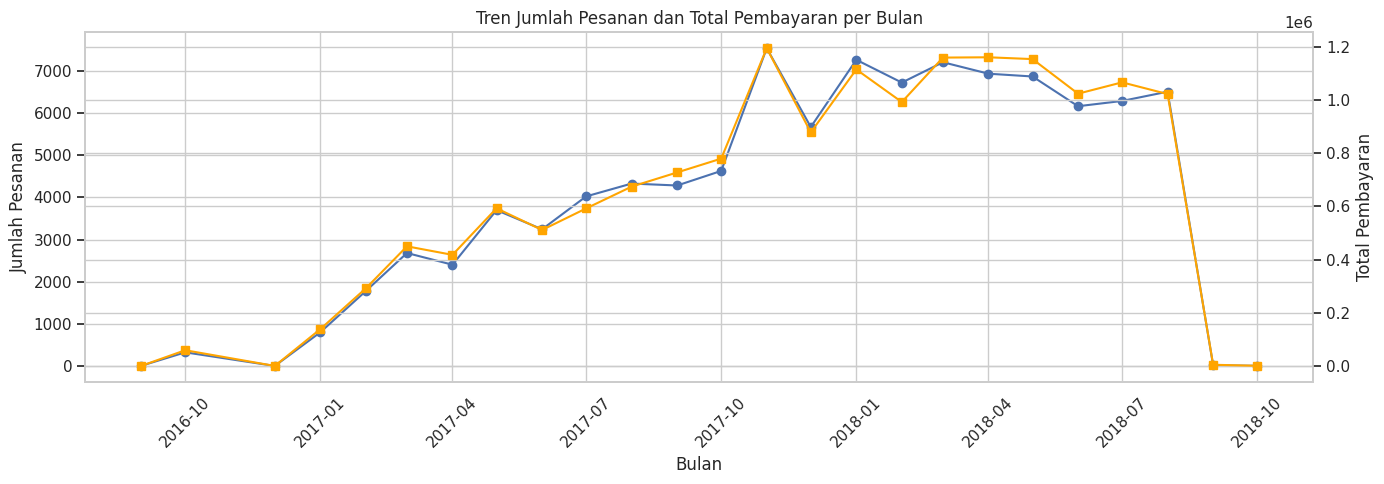

In [15]:
fig, ax1 = plt.subplots(figsize=(14, 5))
x = pd.to_datetime(sales_monthly["order_month"])
ax1.plot(x, sales_monthly["total_orders"], marker="o", label="Jumlah Pesanan")
ax1.set_xlabel("Bulan")
ax1.set_ylabel("Jumlah Pesanan")
ax1.tick_params(axis="x", rotation=45)
ax2 = ax1.twinx()
ax2.plot(x, sales_monthly["total_payment"], marker="s", color="orange", label="Total Pembayaran")
ax2.set_ylabel("Total Pembayaran")
ax1.set_title("Tren Jumlah Pesanan dan Total Pembayaran per Bulan")
fig.tight_layout()
plt.show()

### Pertanyaan 2: Tingkat keterlambatan pengiriman per negara bagian

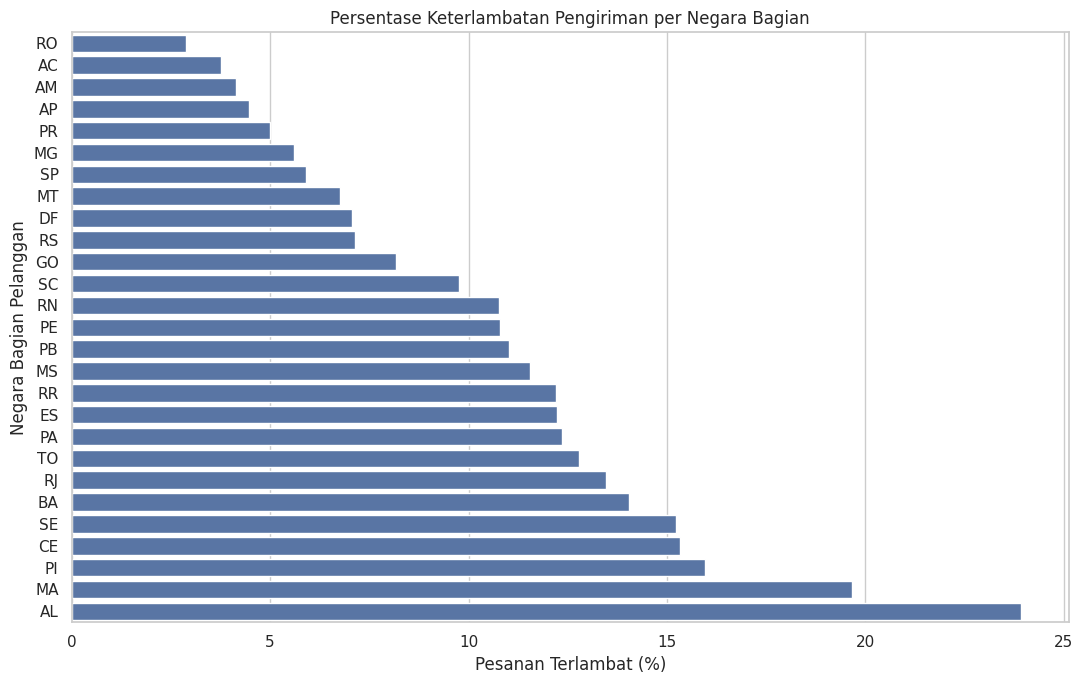

In [16]:
plot_delivery = delivery_by_state.sort_values("late_rate_pct", ascending=True)
plt.figure(figsize=(11, 7))
sns.barplot(data=plot_delivery, x="late_rate_pct", y="customer_state")
plt.xlabel("Pesanan Terlambat (%)")
plt.ylabel("Negara Bagian Pelanggan")
plt.title("Persentase Keterlambatan Pengiriman per Negara Bagian")
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Grafik tren bulanan memperlihatkan kenaikan aktivitas transaksi dari akhir 2016 hingga 2017. Puncak kedua metrik terjadi pada November 2017, dengan 7.544 pesanan dan total pembayaran 1.194.882,80. Pada 2018, transaksi masih relatif tinggi hingga Agustus. Nilai yang sangat rendah pada September dan Oktober 2018 perlu ditafsirkan hati-hati karena periode data berakhir pada 17 Oktober 2018 dan bagian akhir dataset tidak lengkap.
- Grafik keterlambatan per negara bagian menunjukkan variasi performa pengiriman. AL memiliki persentase tertinggi (23,93%), diikuti MA (19,67%) dan PI (15,97%). Sebaliknya, RO (2,88%), AC (3,75%), dan AM (4,14%) memiliki persentase terendah pada data yang tersedia.
- Persentase tertinggi tidak selalu berarti jumlah kasus terbesar. RJ mencatat 1.664 keterlambatan dan SP mencatat 2.387 keterlambatan, sehingga kedua wilayah tersebut juga relevan untuk evaluasi operasional meskipun persentase keterlambatannya lebih rendah daripada AL atau MA.
- Kedua visualisasi menjawab pertanyaan bisnis dengan sudut pandang berbeda: grafik pertama menggambarkan perkembangan transaksi, sedangkan grafik kedua membantu mengidentifikasi wilayah yang perlu dievaluasi berdasarkan proporsi dan jumlah keterlambatan.

## Analisis Lanjutan (Opsional)

RFM digunakan untuk mengelompokkan pelanggan berdasarkan Recency (jarak hari sejak transaksi terakhir), Frequency (jumlah pesanan), dan Monetary (total nilai pembayaran).

In [17]:
rfm_base = orders_analysis.dropna(subset=["order_purchase_timestamp", "customer_unique_id"]).copy()
rfm_base = rfm_base[rfm_base["payment_value"].notna()]
snapshot_date = rfm_base["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm = rfm_base.groupby("customer_unique_id").agg(
    Recency=("order_purchase_timestamp", lambda x: (snapshot_date - x.max()).days),
    Frequency=("order_id", "nunique"),
    Monetary=("payment_value", "sum")
).reset_index()

rfm["R_score"] = pd.qcut(rfm["Recency"].rank(method="first"), 4, labels=[4, 3, 2, 1]).astype(int)
rfm["F_score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["M_score"] = pd.qcut(rfm["Monetary"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["RFM_score"] = rfm["R_score"].astype(str) + rfm["F_score"].astype(str) + rfm["M_score"].astype(str)

def segment_customer(row):
    if row["R_score"] >= 3 and row["F_score"] >= 3 and row["M_score"] >= 3:
        return "Best Customers"
    if row["R_score"] >= 3 and row["F_score"] <= 2:
        return "Recent Customers"
    if row["R_score"] <= 2 and row["F_score"] >= 3:
        return "At Risk"
    return "Others"

rfm["Segment"] = rfm.apply(segment_customer, axis=1)
rfm_summary = rfm.groupby("Segment", as_index=False).agg(
    customers=("customer_unique_id", "count"),
    avg_recency=("Recency", "mean"),
    avg_frequency=("Frequency", "mean"),
    avg_monetary=("Monetary", "mean")
)
display(rfm_summary)
rfm.to_csv("rfm_customer_segments.csv", index=False)

,Segment,customers,avg_recency,avg_frequency,avg_monetary
0,At Risk,23967,414.898944,1.060500,168.621576
1,Best Customers,12589,161.979824,1.135753,274.720612
2,Others,35571,333.961795,1.005229,130.302514
3,Recent Customers,23968,162.015187,1.000000,161.635108


**Insight:** (Opsional)
- Segmentasi menghasilkan empat kelompok pelanggan: At Risk (23.967 pelanggan), Best Customers (12.589 pelanggan), Others (35.571 pelanggan), dan Recent Customers (23.968 pelanggan).
- Segmen Best Customers memiliki rata-rata nilai pembayaran tertinggi dan frekuensi transaksi tertinggi, sehingga layak dipertahankan melalui program loyalitas.
- Segmen At Risk berisi 23.967 pelanggan dengan jarak transaksi terakhir yang relatif lama menjadi indikasi bahwa kelompok ini perlu dipertimbangkan untuk kampanye win-back.
- Recent Customers dapat diarahkan untuk melakukan pembelian kedua melalui rekomendasi produk atau promosi pembelian berikutnya.
- Segmen Others merupakan kelompok terbesar.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** "Bagaimana perkembangan jumlah pesanan dan total nilai pembayaran (GMV) per bulan pada transaksi Olist selama periode data 2016–2018?"
> Aktivitas transaksi Olist meningkat pesat dari akhir 2016 sepanjang 2017, kemudian berada pada tingkat yang relatif tinggi selama 2018 hingga Agustus. Puncak jumlah pesanan dan total pembayaran terjadi pada November 2017, masing-masing sebesar 7.544 pesanan dan 1.194.882,80. Total selama periode analisis mencapai 99.441 pesanan dan 16.008.872,00 total pembayaran. Angka yang rendah pada September–Oktober 2018 tidak dapat langsung dianggap sebagai penurunan bisnis karena data pembelian berakhir pada 17 Oktober 2018 dan periode terakhir tidak lengkap.
- **Conclusion pertanyaan 2:** "Bagaimana tingkat keterlambatan pengiriman pesanan yang telah terkirim menurut negara bagian pelanggan selama periode data 2016–2018, dan negara bagian mana yang perlu diprioritaskan?"
> Keterlambatan pengiriman berdasarkan negara bagian: Dari 96.470 pesanan terkirim yang dapat dianalisis, terdapat 7.826 pesanan terlambat, atau sekitar 8,11% secara keseluruhan (weighted rate). Berdasarkan persentase per negara bagian, AL memiliki tingkat keterlambatan tertinggi sebesar 23,93%, diikuti MA (19,67%) dan PI (15,97%). Namun, jumlah kasus juga perlu dipertimbangkan: SP mencatat 2.387 keterlambatan dan RJ 1.664 keterlambatan, yang merupakan jumlah absolut terbesar. Karena itu, prioritas perbaikan perlu membedakan wilayah dengan tingkat keterlambatan tinggi dan wilayah dengan volume kasus tinggi.

- Analisis lanjutan –> Segmentasi RFM: Hasil RFM membagi pelanggan menjadi empat segmen. Terdapat 12.589 Best Customers dengan rata-rata monetary tertinggi (274,72), sedangkan 23.967 pelanggan At Risk memiliki rata-rata recency tertinggi (414,90 hari). Temuan ini dapat digunakan untuk menyusun strategi retensi yang berbeda bagi pelanggan bernilai tinggi, pelanggan yang mulai tidak aktif, dan pelanggan baru.

**Rekomendasi Action Item:**
- Prioritas dapat diberikan kepada wilayah AL, MA, dan PI dengan memeriksa performa mitra pengiriman, estimasi waktu pengiriman, serta kendala distribusi yang terjadi.
- Olist dapat memanfaatkan periode dengan aktivitas transaksi tinggi, khususnya menjelang akhir tahun seperti November, untuk menjalankan kampanye promosi dan memastikan ketersediaan stok serta kapasitas operasional.
- Berdasarkan segmentasi RFM, hasil segmentasi menunjukkan terdapat 23.967 pelanggan dalam kategori At Risk dan 12.589 pelanggan dalam kategori Best Customers. Olist dapat memberikan promosi atau penawaran khusus untuk menarik kembali pelanggan At Risk, sekaligus mempertahankan loyalitas pelanggan Best Customers melalui program loyalitas dan penawaran eksklusif.

In [ ]:
orders_analysis.to_csv("main_data.csv", index=False)